# Evaluating the gas chain on real smoke recordings

**Full data set, two independent burns, default settings.** This notebook is the evidence behind the gas chain results of the project (research log RES-GAS-1 to 6). It states the protocol before the numbers, reports what the chain does on real recordings, diagnoses where it fails, and lists what the data cannot show. For a stage-by-stage explanation of the chain itself, see `02_stage_by_stage_demo.ipynb`.

**Abstract.** On 38 episodes (13 097 scans) of two burns recorded with BME688/690 sensors, the chain with default settings meets the six pre-set criteria: false smoke on clean air 0.0 % (2021) and 1.9 % (2025), recall in strong smoke 1.000, no sensor fault, median delay about 3 minutes. The only false smoke comes from 4 episodes of one node with a slow scan and few clean scans, and in those episodes the false alarm **latches**. Temperature and humidity compensation fitted on one burn does not carry over to the other. A longer burn-in or warm-up does not help. The median filter costs about one minute. The data holds no weak response, so sensitivity can only be probed with a distance proxy.

**Sensor caveat.** The data come from a BME688/690; the box uses a **BME680**. Every number here is a cross-check on a sibling sensor, not a validation of the target sensor.

**Contents.** 1 Protocol · 2 Data · 3 Default results · 4 Where false smoke comes from · 5 Compensation · 6 Burn-in and warm-up · 7 Median window · 8 Sensitivity · 9 Verdict and limits.

In [1]:
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")
from gas_chain import GasChain, Config, NORMAL, SMOKE, FAULT
from gas_chain.data_mendeley import load_all
from gas_chain.evaluate import replay, metrics, dilute, fit_compensation, response_depth, STRONG_PHASES

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
BURN_COLOR = {"2021": "#1f77b4", "2025": "#d95f02"}

## 1. Protocol

**Question.** With its default configuration, does the chain detect real smoke without false alarms and without mistaking a plume for a broken sensor?

**Design.**
- **One fresh chain per episode** (one file and one sensor), replayed scan by scan in time order, exactly as on the box.
- **Split by burn, never inside a file.** The 2021 burn (node 1) and the 2025 burn (nodes 2 to 5) are independent recordings. Settings are never tuned on one burn and judged on the same one without saying so.
- **Truth labels.** The authors' phase tags are undocumented, so phases are numbered by order: phase 0 is the clean start, phase 1 shows no response, phase 2 is the onset, phases 3 to 5 hold the strong smoke, phases 6 and 7 are the decay. *Clean air* = phase 0 after the chain's warm-up. *Strong smoke* = phases 3 to 5.

**Metrics.** Let $\mathcal{C}$ be the clean-air scans after warm-up, $\mathcal{S}$ the strong-smoke scans, and $\hat c_t$ the class given by the chain.
$$
\mathrm{FS}=\frac{|\{t\in\mathcal{C}:\hat c_t=\text{smoke}\}|}{|\mathcal{C}|},\qquad
\mathrm{Recall}=\frac{|\{t\in\mathcal{S}:\hat c_t=\text{smoke}\}|}{|\mathcal{S}|},\qquad
\mathrm{Fault}=\frac{|\{t\in\mathcal{S}:\hat c_t=\text{fault}\}|}{|\mathcal{S}|}
$$
$$
\Delta=\operatorname*{median}_{e}\Big(t^{(e)}_{\text{first smoke}}-t^{(e)}_{\text{phase 2}}\Big)
$$
The delay is counted from the first scan of phase 2 (the first phase with a response) to the first scan classed as smoke.

**Pass criteria, set before the final numbers were seen** (fiche of the gas chain): $\mathrm{FS}\le 2\,\%$, $\mathrm{Recall}\ge0.95$, $\mathrm{Fault}\le1\,\%$, for each burn.

**What the numbers are.** Counts of *scans*, not of independent events: consecutive scans are strongly correlated, and there are two burns. A rate is therefore a description of these recordings, not an estimate with a tight confidence interval.

## 2. The data

The figure shows the **physical size of the response** per phase: the drop of $\ln R$ against the clean start of the same episode, taken as the maximum over the three heater bands (`response_depth`). It is a truth that does not depend on the chain, and shows what the labels mean in physical terms.

 burn  episodes   scans  clean  strong  median dt (s)
 2021         8    2593    581     928             27
 2025        30   10504   1810    4003             24
Median response by phase (all episodes): P0:+0.02 P1:-0.04 P2:+2.03 P3:+3.45 P4:+4.02 P5:+3.39 P6:+1.08 P7:+0.97


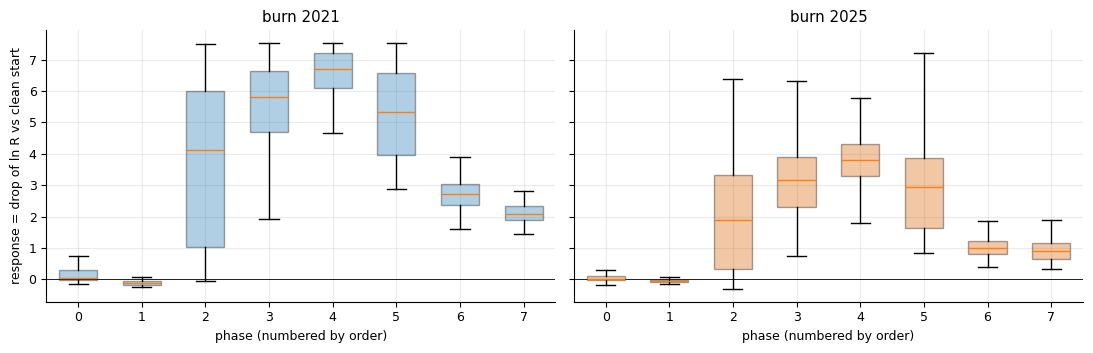

In [2]:
D = load_all()
RD = response_depth(D)
print(f"{'burn':>5} {'episodes':>9} {'scans':>7} {'clean':>6} {'strong':>7} {'median dt (s)':>14}")
for e in ("2021", "2025"):
    m = D["experiment"] == e
    print(f"{e:>5} {len(set(D['episode'][m])):>9} {m.sum():>7} {(m & (D['phase']==0)).sum():>6} "
          f"{(m & np.isin(D['phase'], STRONG_PHASES)).sum():>7} {np.median(D['dt'][m]):>14.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, e in zip(ax, ("2021", "2025")):
    data = [RD[(D["experiment"] == e) & (D["phase"] == p)] for p in range(8)]
    bp = a.boxplot(data, positions=range(8), widths=0.6, showfliers=False, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set(facecolor=BURN_COLOR[e], alpha=0.35)
    a.axhline(0, color="k", lw=0.6)
    a.set(xlabel="phase (numbered by order)", title=f"burn {e}", xticks=range(8))
ax[0].set_ylabel("response = drop of ln R vs clean start")
plt.tight_layout(); plt.show()
print("Median response by phase (all episodes):", " ".join(f"P{p}:{np.median(RD[D['phase']==p]):+.2f}" for p in range(8)))

**Reading.** Phase 0 sits at zero by construction. Phase 1 stays at zero: no response. The onset (phase 2) is already large, the strong phases (3 to 5) have a median drop of about 3.4 to 4.0 $\ln$ units over all episodes (a factor of 30 to 55 on the resistance; the 2021 burn is much stronger, with a median up to about 6.7 in phase 4, against about 3.8 for 2025), and the decay phases (6 and 7) stay about 1 $\ln$ unit below the clean level. Two consequences for the evaluation: the labelled phases are physically distinct, and **no strong-phase scan has a weak response** (see section 8).

## 3. Default results

All settings are the defaults of `Config`: median of 5, smoothing 0.35, burn-in 6, warm-up 6, no compensation, decoy off.

default, burn 2021     false smoke   0.0 %   recall 1.000   fault  0.0 %   never called 0   delay   3.1 min
default, burn 2025     false smoke   1.9 %   recall 1.000   fault  0.0 %   never called 0   delay   3.2 min
default, both          false smoke   1.4 %   recall 1.000   fault  0.0 %   never called 0   delay   3.1 min


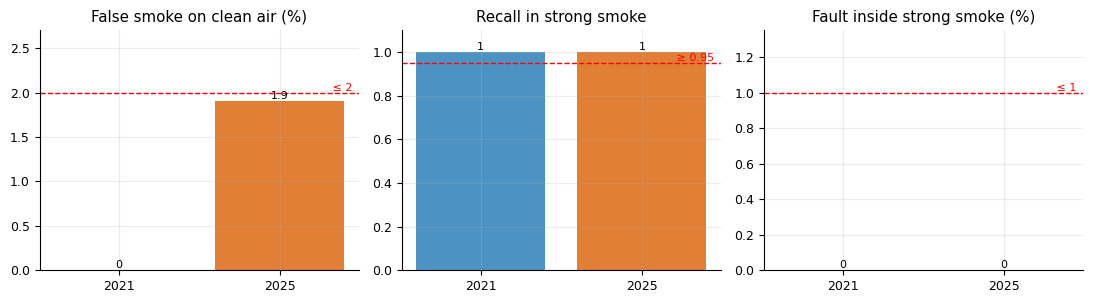

In [3]:
def row(tag, m):
    print(f"{tag:<22} false smoke {m['false_smoke_clean']*100:5.1f} %   recall {m['recall_strong']:.3f}   "
          f"fault {m['fault_in_strong']*100:4.1f} %   never called {m['episodes_never_called']}   "
          f"delay {m['delay_min_median']:5.1f} min")

res = replay(D)
M = {e: metrics(D, res, e, start_phase=2) for e in ("2021", "2025")}
for e in ("2021", "2025"):
    row(f"default, burn {e}", M[e])
row("default, both", metrics(D, res, None, start_phase=2))

fig, ax = plt.subplots(1, 3, figsize=(11, 3.1))
items = [("false_smoke_clean", "False smoke on clean air (%)", 100, 2.0, "≤"), ("recall_strong", "Recall in strong smoke", 1, 0.95, "≥"),
         ("fault_in_strong", "Fault inside strong smoke (%)", 100, 1.0, "≤")]
for a, (k, title, scale, limit, sign) in zip(ax, items):
    vals = [M[e][k] * scale for e in ("2021", "2025")]
    a.bar(["2021", "2025"], vals, color=[BURN_COLOR[e] for e in ("2021", "2025")], alpha=0.8)
    a.axhline(limit, color="r", ls="--", lw=1); a.text(1.45, limit, f" {sign} {limit:g}", color="r", va="bottom", ha="right", fontsize=8)
    a.set(title=title); a.set_ylim(0, max(max(vals), limit) * 1.35 if k != "recall_strong" else 1.1)
    for i, v in enumerate(vals):
        a.text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

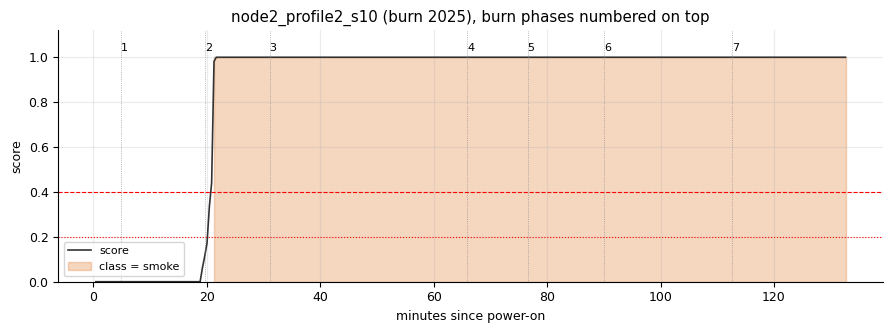

In [4]:
# What a normal run looks like: one 2025 episode (node 2), score and class against the burn phases
ep = [i for i, k in enumerate(D["kind"]) if k.startswith("node2_profile2")][0]
m = D["episode"] == ep
t = np.cumsum(D["dt"][m]) / 60.0
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, res["score"][m], color="#333", lw=1.2, label="score")
ax.fill_between(t, 0, 1, where=res["cls"][m] == SMOKE, color="#d95f02", alpha=0.25, label="class = smoke")
for ph in range(1, 8):
    first = np.flatnonzero(D["phase"][m] == ph)
    if len(first):
        ax.axvline(t[first[0]], color="#888", lw=0.5, ls=":"); ax.text(t[first[0]], 1.03, str(ph), fontsize=8, ha="left")
ax.axhline(0.40, color="r", ls="--", lw=0.8); ax.axhline(0.20, color="r", ls=":", lw=0.8)
ax.set(xlabel="minutes since power-on", ylabel="score", ylim=(0, 1.12), title=f"{D['kind'][ep]} (burn 2025), burn phases numbered on top")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

**Reading.**
- Both burns pass the three criteria. Recall is 1.000 and no strong-smoke scan is read as a sensor fault.
- The delay from the onset to the first smoke scan is about 3 minutes (3.1 and 3.2 min), i.e. 7 scans at the recorded pace of 25 to 27 s.
- Two margins are thin: **false smoke in 2025 is 1.9 % against a 2 % limit**, and, as the next section shows, it rests on a handful of episodes.

## 4. Where does the false smoke come from?

**Hypothesis.** The false smoke is not spread over the data set: it comes from episodes where the baseline is learned from too little clean air, namely few clean scans after the warm-up and a slow scan period.

**Method.** For every episode with clean scans after the warm-up, compare the false-smoke rate with the number of clean scans and the scan period.

burn 2021: 8 episodes, 8 with clean scans after the warm-up (scored), 0 with false smoke, 0 not evaluable
burn 2025: 30 episodes, 22 with clean scans after the warm-up (scored), 4 with false smoke, 8 not evaluable

Episodes with false smoke on clean air:
  node3_profile2_s18     burn 2025  clean scans  15  false   67 %  median dt 77 s
  node3_profile2_s19     burn 2025  clean scans  15  false   53 %  median dt 78 s
  node3_profile3_s20     burn 2025  clean scans   7  false   71 %  median dt 111 s
  node3_profile3_s21     burn 2025  clean scans   7  false   71 %  median dt 111 s

The 26 other scored episodes: clean scans 23 to 180 (median 70), scan period 11 to 38 s.

Share of clean scans with heater steps 0 and 1 at the sensor saturation (102.4 Mohm):
  the 4 failing episodes   : 96 %, 96 %, 95 %, 95 %
  the 26 other scored ones : maximum 87 % | number with any saturation: 11


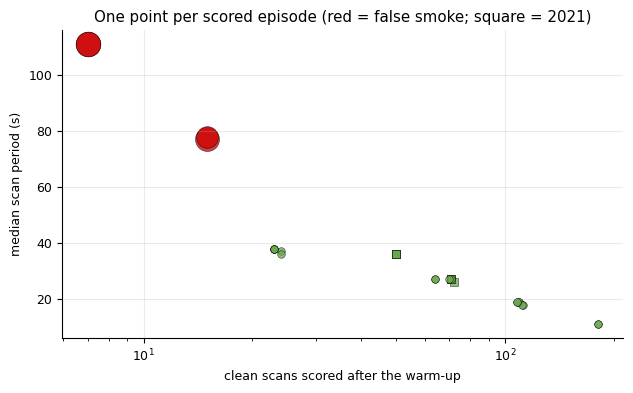

In [5]:
live = ~res["warmup"]
eps = np.unique(D["episode"])
tab = []
for ep_ in eps:
    mm = D["episode"] == ep_
    clean_ = mm & (D["phase"] == 0) & live
    n = int(clean_.sum())
    tab.append(dict(ep=ep_, kind=D["kind"][ep_], burn=D["experiment"][mm][0], n=n, dt=float(np.median(D["dt"][mm])),
                    fs=float((res["cls"][clean_] == SMOKE).mean()) if n else np.nan))
for e in ("2021", "2025"):
    sub = [r for r in tab if r["burn"] == e]
    ok = [r for r in sub if r["n"] > 0]
    bad = [r for r in ok if r["fs"] > 0]
    print(f"burn {e}: {len(sub)} episodes, {len(ok)} with clean scans after the warm-up (scored), {len(bad)} with false smoke, {len(sub)-len(ok)} not evaluable")
print("\nEpisodes with false smoke on clean air:")
for r in tab:
    if r["n"] and r["fs"] > 0:
        print(f"  {r['kind']:<22} burn {r['burn']}  clean scans {r['n']:>3}  false {r['fs']*100:4.0f} %  median dt {r['dt']:.0f} s")
good = [r for r in tab if r["n"] and r["fs"] == 0]
print(f"\nThe {len(good)} other scored episodes: clean scans {min(r['n'] for r in good)} to {max(r['n'] for r in good)} "
      f"(median {np.median([r['n'] for r in good]):.0f}), scan period {min(r['dt'] for r in good):.0f} to {max(r['dt'] for r in good):.0f} s.")

SAT = np.log(102.4e6)          # sensor saturation, 102.4 Mohm
def sat_share(ep_):
    mm = (D["episode"] == ep_) & (D["phase"] == 0)
    return float((np.log(D["gas"][mm]) >= SAT - 0.01).mean(0)[:2].mean())
print("\nShare of clean scans with heater steps 0 and 1 at the sensor saturation (102.4 Mohm):")
print("  the 4 failing episodes   :", ", ".join(f"{sat_share(r['ep'])*100:.0f} %" for r in tab if r["n"] and r["fs"] > 0))
print("  the 26 other scored ones : maximum", f"{max(sat_share(r['ep']) for r in good)*100:.0f} %", "| number with any saturation:", sum(sat_share(r["ep"]) > 0 for r in good))

fig, ax = plt.subplots(figsize=(6.4, 4))
for r in tab:
    if not r["n"]:
        continue
    ax.scatter(r["n"], r["dt"], s=30 + 400 * r["fs"], c="#cc0000" if r["fs"] > 0 else "#6aa84f", alpha=0.75,
               marker="o" if r["burn"] == "2025" else "s", edgecolor="k", lw=0.4)
ax.set(xscale="log", xlabel="clean scans scored after the warm-up", ylabel="median scan period (s)",
       title="One point per scored episode (red = false smoke; square = 2021)")
plt.tight_layout(); plt.show()

**Reading.**
- All the false smoke sits in **4 of the 30 scored episodes**: node 3, heater profiles 2 and 3. They are the only episodes with a scan period of 77 s or more, and have only 7 to 15 clean scans. Every other scored episode has at least 23 clean scans and a scan period of at most 38 s.
- **8 episodes of 2025 are not evaluable** on clean air: their clean start is shorter than burn-in plus window plus warm-up. They add nothing to the false-smoke rate. The 1.9 % of 2025 is therefore 4 failing episodes out of 22 scored, not out of 30.
- The hypothesis is supported, but on 4 episodes of one node, so it is a **correlation, not a demonstrated cause**: all four share one node, one scan period, a short clean start and the same sensor, and these cannot be separated.

The next question is what happens *after* a false alarm. Phase 1 is a period with no response, so any smoke call there is also false, although the fiche criterion only scores phase 0.

Smoke calls in phase 1 (no physical response):
  burn 2021:  0.0 % of 217 scans
  burn 2025:  4.1 % of 930 scans

Episodes with smoke calls in phase 1:
  node2_profile4_s14      3 of 19 scans  (largest physical response in phase 1: +0.41 ln)
  node3_profile2_s18     11 of 11 scans  (largest physical response in phase 1: +0.33 ln)
  node3_profile2_s19     10 of 10 scans  (largest physical response in phase 1: -0.01 ln)
  node3_profile3_s20      7 of  7 scans  (largest physical response in phase 1: +0.02 ln)
  node3_profile3_s21      7 of  7 scans  (largest physical response in phase 1: +0.04 ln)


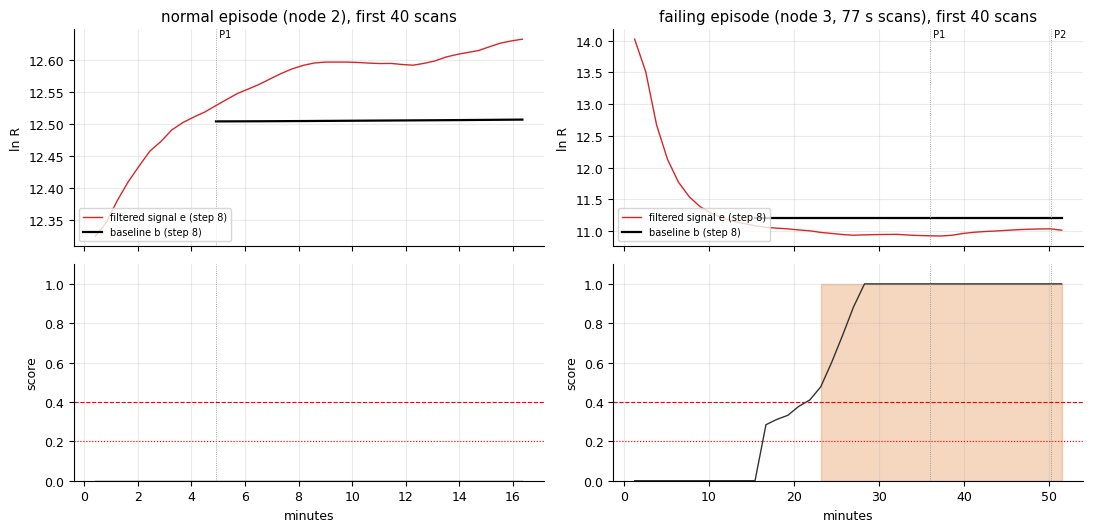

In [6]:
print("Smoke calls in phase 1 (no physical response):")
for e in ("2021", "2025"):
    mm = live & (D["phase"] == 1) & (D["experiment"] == e)
    print(f"  burn {e}: {(res['cls'][mm] == SMOKE).mean()*100:4.1f} % of {mm.sum()} scans")
print("\nEpisodes with smoke calls in phase 1:")
for ep_ in eps:
    mm = live & (D["phase"] == 1) & (D["episode"] == ep_)
    if mm.any() and (res["cls"][mm] == SMOKE).any():
        c = int((res["cls"][mm] == SMOKE).sum())
        print(f"  {D['kind'][ep_]:<22} {c:>2} of {mm.sum():>2} scans  (largest physical response in phase 1: {RD[mm].max():+.2f} ln)")

# internals of one failing episode and one normal episode
def run_chain(ep_):
    idx = np.flatnonzero(D["episode"] == ep_)
    c = GasChain(); out = dict(score=[], cls=[], ema=[], base=[])
    for i in idx:
        r = c.update(D["gas"][i], D["temp"][i], D["rh"][i], D["dt"][i])
        out["score"].append(r.score); out["cls"].append(r.cls)
        out["ema"].append(np.full(10, np.nan) if c.ema is None else c.ema.copy())
        out["base"].append(np.full(10, np.nan) if c.base is None else c.base.copy())
    o = {k: np.array(v) for k, v in out.items()}
    o.update(t=np.cumsum(D["dt"][idx]) / 60.0, phase=D["phase"][idx], idx=idx)
    return o

bad_ep = [i for i, k in enumerate(D["kind"]) if k == "node3_profile2_s18"][0]
good_ep = [i for i, k in enumerate(D["kind"]) if k.startswith("node2_profile2")][0]
fig, ax = plt.subplots(2, 2, figsize=(11, 5.4), sharex="col")
for col, (ep_, title) in enumerate(((good_ep, "normal episode (node 2)"), (bad_ep, "failing episode (node 3, 77 s scans)"))):
    o = {k: v[:40] for k, v in run_chain(ep_).items()}      # zoom on the first 40 scans: warm-up and the start of the alarm
    ax[0, col].plot(o["t"], o["ema"][:, 8], color="tab:red", lw=1, label="filtered signal e (step 8)")
    ax[0, col].plot(o["t"], o["base"][:, 8], color="k", lw=1.6, label="baseline b (step 8)")
    ax[0, col].set(title=title + ", first 40 scans", ylabel="ln R"); ax[0, col].legend(fontsize=7, loc="lower left")
    ax[1, col].plot(o["t"], o["score"], color="#333", lw=1)
    ax[1, col].fill_between(o["t"], 0, 1, where=o["cls"] == SMOKE, color="#d95f02", alpha=0.25)
    ax[1, col].axhline(0.20, color="r", ls=":", lw=0.8); ax[1, col].axhline(0.40, color="r", ls="--", lw=0.8)
    ax[1, col].set(xlabel="minutes", ylabel="score", ylim=(0, 1.1))
    for ph in range(1, 3):
        f = np.flatnonzero(o["phase"] == ph)
        if len(f):
            for a in ax[:, col]:
                a.axvline(o["t"][f[0]], color="#888", lw=0.6, ls=":")
            ax[0, col].text(o["t"][f[0]], ax[0, col].get_ylim()[1], f" P{ph}", va="top", fontsize=7)
plt.tight_layout(); plt.show()

**Reading.**
- In the four failing episodes the false alarm **latches**: 35 smoke calls out of 35 scans of phase 1, although the physical response there is about zero (median between $-0.04$ and $+0.02$ ln; the largest single scan is $+0.33$ ln). A fifth episode has 3 calls in phase 1 with a small response (up to 0.41 $\ln$ units), which may be real.
- **Mechanism, read on the right-hand figure** (step 8 shown; the other high-temperature steps behave the same). The baseline is learned from the 6 scans that follow the burn-in, shortly after power-on. In this episode the sensor starts far from its operating point: the filtered signal of step 8 falls from about 14 to 11 $\ln$ units within roughly ten minutes. The baseline is learned on the tail of that transient (about 11.2), and the signal then settles slightly lower (about 10.95), a gap of about 0.25. In the normal episode on the left the signal settles above its baseline, so the depth stays negative. The baseline follows with a time constant of 6 h, which corrects only about 0.4 % of a gap per 77 s scan, so the gap stays. Because the depth (0.1 to 0.17) is above the CUSUM allowance $k=0.03$, the CUSUM builds up, the score crosses 0.40 five scans after the baseline exists, and the class turns to smoke.
- **Then the baseline is frozen** (stage 4 freezes it while the class is not normal). Nothing can correct the error afterwards, and the score stays above the release threshold. The freeze that protects against absorbing a real fire also prevents recovery from a false alarm: a **design weakness, not noise**.
- **What is not the cause.** The low-heater steps 0 and 1 sit at the sensor saturation (102.4 MΩ) in 95 to 96 % of the clean scans of the four failing episodes, but also in 11 of the 26 other scored episodes (up to 87 %), without false smoke. Saturation alone does not explain the false alarm, and a saturated step carries no information in clean air (it can only fall).
- The fiche criterion scores phase 0 only. Phase 1 is a stricter test on the same recordings: in 2025, 4.1 % of the scans of phase 1 are called smoke, against 0.0 % in 2021.
- **Remedies, not yet tried:** a release rule after a long quiet period, a baseline saved in flash (so that it is not learned while the sensor settles), a longer warm-up for slow scans (section 6 suggests it does not help on average), or fusion with the other sensors on the gateway.

## 5. Temperature and humidity compensation

**Question.** Can the effect of temperature and humidity on $\ln R$ be fitted on clean air and then applied to another burn?

**Method.** Least-squares fit of $a_T$ and $b_H$ on clean scans only, with $\ln R$, $T$ and RH centred per run and per heater step, so that only the co-movement inside a run counts. The fit on one burn is then applied to the other (with $b_H=0$).
$$
x_i=\ln R_i-a_T\,(T-25)-b_H\,(\mathrm{RH}-50)
$$

Compensation fitted on clean air (ln R per degC, ln R per % RH, R2):
  fit on burn 2021: a_t -0.143  b_h -0.003  R2 0.35
  fit on burn 2025: a_t -0.132  b_h -0.110  R2 0.06

Applied to the other burn (b_h kept at 0):
a_t = 0, judge 2025    false smoke   1.9 %   recall 1.000   fault  0.0 %   never called 0   delay   3.2 min
a_t fitted on 2021, judge 2025 false smoke   1.2 %   recall 0.993   fault  0.0 %   never called 0   delay   6.8 min
a_t = 0, judge 2021    false smoke   0.0 %   recall 1.000   fault  0.0 %   never called 0   delay   3.1 min
a_t fitted on 2025, judge 2021 false smoke  25.4 %   recall 1.000   fault  0.0 %   never called 0   delay   3.3 min


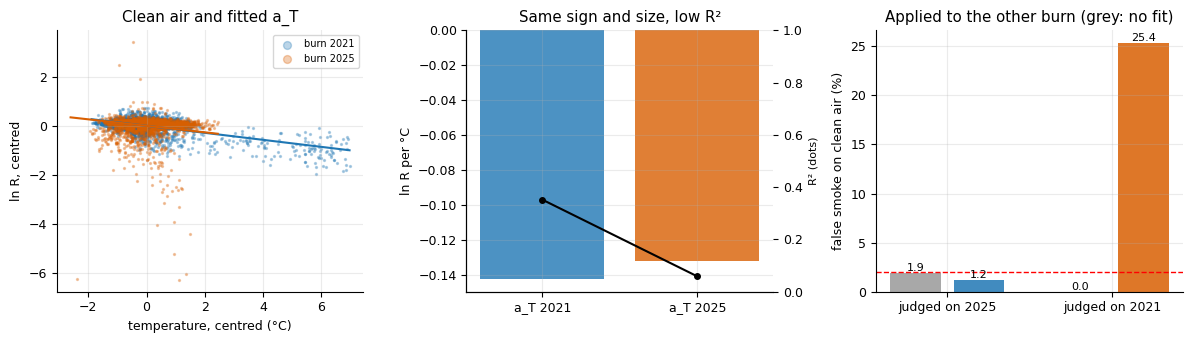

In [7]:
clean = D["phase"] == 0
print("Compensation fitted on clean air (ln R per degC, ln R per % RH, R2):")
fits = {}
for e in ("2021", "2025"):
    fits[e] = fit_compensation(D, clean & (D["experiment"] == e))
    print(f"  fit on burn {e}: a_t {fits[e][0]:+.3f}  b_h {fits[e][1]:+.3f}  R2 {fits[e][2]:.2f}")
print()
print("Applied to the other burn (b_h kept at 0):")
comp = {}
for fit_on, judge in (("2021", "2025"), ("2025", "2021")):
    for tag, a in (("a_t = 0", 0.0), (f"a_t fitted on {fit_on}", fits[fit_on][0])):
        r = replay(D, replace(Config(), a_t=a))
        mm = metrics(D, r, judge, start_phase=2)
        comp[(judge, tag)] = mm
        row(f"{tag}, judge {judge}", mm)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
rng = np.random.default_rng(0)
for e in ("2021", "2025"):
    ys, ts = [], []
    for ep_ in np.unique(D["episode"][(D["experiment"] == e)]):
        mm = clean & (D["episode"] == ep_)
        if mm.sum() < 5:
            continue
        ys.append((np.log(D["gas"][mm]) - np.log(D["gas"][mm]).mean(0)).ravel()); ts.append((D["temp"][mm] - D["temp"][mm].mean(0)).ravel())
    y, t_ = np.concatenate(ys), np.concatenate(ts)
    pick = rng.choice(len(y), size=min(3000, len(y)), replace=False)
    ax[0].scatter(t_[pick], y[pick], s=2, alpha=0.3, color=BURN_COLOR[e], label=f"burn {e}")
    xs = np.linspace(t_.min(), t_.max(), 2); ax[0].plot(xs, fits[e][0] * xs, color=BURN_COLOR[e], lw=1.5)
ax[0].set(xlabel="temperature, centred (°C)", ylabel="ln R, centred", title="Clean air and fitted a_T"); ax[0].legend(fontsize=7, markerscale=4)
ax[1].bar(["a_T 2021", "a_T 2025"], [fits["2021"][0], fits["2025"][0]], color=[BURN_COLOR["2021"], BURN_COLOR["2025"]], alpha=0.8)
ax2 = ax[1].twinx(); ax2.grid(False)
ax2.plot(["a_T 2021", "a_T 2025"], [fits["2021"][2], fits["2025"][2]], "ko-", ms=4); ax2.set_ylabel("R² (dots)", fontsize=8); ax2.set_ylim(0, 1)
ax[1].set(ylabel="ln R per °C", title="Same sign and size, low R²")
labels = ["a_T = 0", "a_T fitted on the other burn"]
for j, (judge, other) in enumerate((("2025", "2021"), ("2021", "2025"))):
    v = [comp[(judge, "a_t = 0")]["false_smoke_clean"] * 100, comp[(judge, f"a_t fitted on {other}")]["false_smoke_clean"] * 100]
    ax[2].bar(np.arange(2) + j * 2.6, v, color=["#999", BURN_COLOR[other]], alpha=0.85)
    for i, val in enumerate(v):
        ax[2].text(i + j * 2.6, val, f"{val:.1f}", ha="center", va="bottom", fontsize=8)
ax[2].set_xticks([0.5, 3.1]); ax[2].set_xticklabels(["judged on 2025", "judged on 2021"])
ax[2].axhline(2, color="r", ls="--", lw=1)
ax[2].set(ylabel="false smoke on clean air (%)", title="Applied to the other burn (grey: no fit)")
plt.tight_layout(); plt.show()

**Reading.**
- The temperature term has the same sign and size in both burns (about $-0.13$ to $-0.14$ ln R per °C). The humidity term does not ($-0.003$ against $-0.110$).
- $R^2$ is 0.35 for 2021 and 0.06 for 2025: temperature explains little of the clean-air variation.
- Applied to the other burn, the fit **does not hold**. Fitted on 2025 and judged on 2021, false smoke goes from 0.0 % to 25.4 %. Fitted on 2021 and judged on 2025, false smoke drops to 1.2 % but the delay doubles (3.2 to 6.8 min) and recall falls to 0.993.
- Likely cause (a hypothesis, not tested): in clean air the temperature moves with the sensor warming up after power-on, so the fit also absorbs settling drift. In the fire, temperature rises by about 6 °C, and a large coefficient would cancel part of the real response.
- **Decision.** $a_T=b_H=0$ for now. The stage stays in the code: the specification makes compensation mandatory, and it needs a controlled temperature and humidity sweep on the **own BME680**.

## 6. Burn-in and warm-up

**Hypothesis (from the earlier work).** Ignoring more scans after power-on (burn-in), or averaging more scans for the first baseline (warm-up), reduces the false smoke caused by power-on drift.

**Method.** Grid over burn-in $\in\{0,6,12,24\}$ and warm-up $\in\{6,12\}$ scans, false smoke on clean air per burn.

False smoke on clean air (%), by burn-in and warm-up length (scans):
 burn-in  warm-up  burn 2021  burn 2025  clean scans 2025
       0        6        0.0        3.2              1518
       0       12        0.0        1.7              1382
       6        6        0.0        1.9              1470
       6       12        2.5        0.3              1338
      12        6        4.1        2.9              1338
      12       12        4.6        3.4              1216
      24        6        5.0        3.6              1102
      24       12        4.8        3.3               998


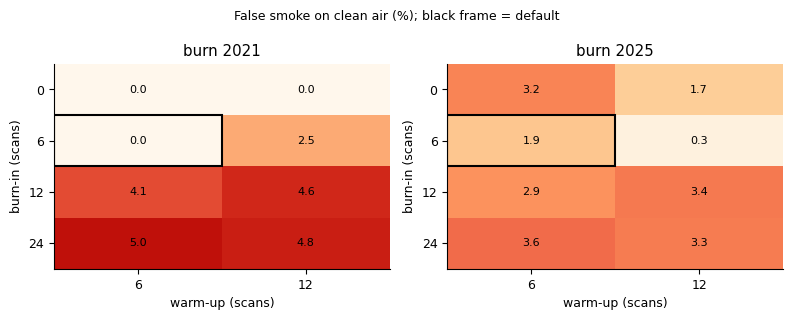

In [8]:
burns_grid, warms_grid = (0, 6, 12, 24), (6, 12)
G = {e: np.zeros((len(burns_grid), len(warms_grid))) for e in ("2021", "2025")}
n25 = np.zeros((len(burns_grid), len(warms_grid)), int)
print("False smoke on clean air (%), by burn-in and warm-up length (scans):")
print(f"{'burn-in':>8} {'warm-up':>8} {'burn 2021':>10} {'burn 2025':>10} {'clean scans 2025':>17}")
for i, b in enumerate(burns_grid):
    for j, w in enumerate(warms_grid):
        r = replay(D, replace(Config(), burnin_scans=b, warmup_scans=w))
        m21, m25 = metrics(D, r, "2021"), metrics(D, r, "2025")
        G["2021"][i, j], G["2025"][i, j], n25[i, j] = m21["false_smoke_clean"] * 100, m25["false_smoke_clean"] * 100, m25["clean_scans"]
        print(f"{b:>8} {w:>8} {G['2021'][i, j]:>10.1f} {G['2025'][i, j]:>10.1f} {n25[i, j]:>17}")

fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
for a, e in zip(ax, ("2021", "2025")):
    im = a.imshow(G[e], cmap="OrRd", vmin=0, vmax=6, aspect="auto")
    a.set(xticks=range(len(warms_grid)), xticklabels=warms_grid, yticks=range(len(burns_grid)), yticklabels=burns_grid,
          xlabel="warm-up (scans)", ylabel="burn-in (scans)", title=f"burn {e}"); a.grid(False)
    for i in range(len(burns_grid)):
        for j in range(len(warms_grid)):
            a.text(j, i, f"{G[e][i, j]:.1f}", ha="center", va="center", fontsize=8)
    a.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, ec="k", lw=1.5))   # default: burn-in 6, warm-up 6
fig.suptitle("False smoke on clean air (%); black frame = default", fontsize=9)
plt.tight_layout(); plt.show()

**Reading.**
- **No trend survives in both burns.** The default (burn-in 6, warm-up 6) gives 0.0 % and 1.9 %; burn-in 24 with warm-up 6 gives 5.0 % and 3.6 %. Burn-in 6 with warm-up 12 is the best for 2025 (0.3 %) and worse for 2021 (2.5 %).
- Longer burn-in also removes clean scans from the denominator (column on the right of the table), so the rate is computed on a smaller and different set.
- Differences of one or two points rest on a handful of scans from a few episodes: treat them as noise.
- The earlier plan "longer conditioning fixes the power-on drift" is **not supported** by this data.
- **Decision.** Keep 6 and 6. The remaining lever is a baseline saved in flash (`snapshot` / `restore`), which needs field data to judge.

## 7. Median window

**Question.** What does the median of 5 scans cost, and what does it buy?

**Method.** Window $w\in\{1,3,5\}$ ($w=1$ means no median). Delay counted from the first scan of phase 2.

Median window: delay counted from the first phase with a response (phase 2).
window 1, burn 2021    false smoke   2.9 %   recall 1.000   fault  0.0 %   never called 0   delay   2.0 min
window 1, burn 2025    false smoke   1.8 %   recall 1.000   fault  0.0 %   never called 0   delay   2.2 min
window 3, burn 2021    false smoke   1.6 %   recall 1.000   fault  0.0 %   never called 0   delay   2.6 min
window 3, burn 2025    false smoke   2.0 %   recall 1.000   fault  0.0 %   never called 0   delay   2.6 min
window 5, burn 2021    false smoke   0.0 %   recall 1.000   fault  0.0 %   never called 0   delay   3.1 min
window 5, burn 2025    false smoke   1.9 %   recall 1.000   fault  0.0 %   never called 0   delay   3.2 min


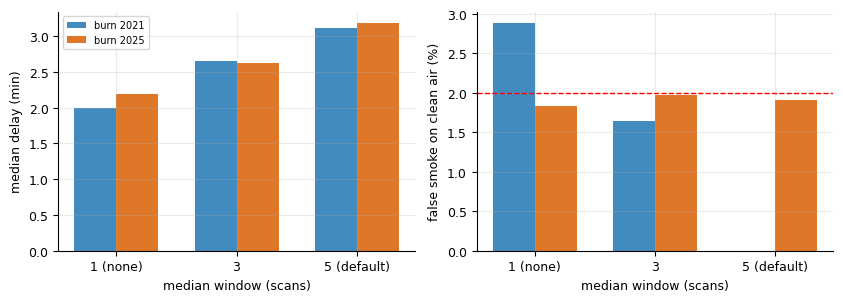

In [9]:
print("Median window: delay counted from the first phase with a response (phase 2).")
W = {e: [] for e in ("2021", "2025")}
for w in (1, 3, 5):
    r = replay(D, replace(Config(), median_window=w))
    for e in ("2021", "2025"):
        mm = metrics(D, r, e, start_phase=2)
        W[e].append(mm); row(f"window {w}, burn {e}", mm)

fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.1))
x = np.arange(3)
for k, e in enumerate(("2021", "2025")):
    ax[0].bar(x + (k - 0.5) * 0.35, [m["delay_min_median"] for m in W[e]], 0.35, color=BURN_COLOR[e], alpha=0.85, label=f"burn {e}")
    ax[1].bar(x + (k - 0.5) * 0.35, [m["false_smoke_clean"] * 100 for m in W[e]], 0.35, color=BURN_COLOR[e], alpha=0.85, label=f"burn {e}")
for a, yl in zip(ax, ("median delay (min)", "false smoke on clean air (%)")):
    a.set(xticks=x, xticklabels=["1 (none)", "3", "5 (default)"], xlabel="median window (scans)", ylabel=yl)
ax[1].axhline(2, color="r", ls="--", lw=1); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading.**
- Median of 5 against no median: the delay grows from 2.0 to 3.1 min (2021) and from 2.2 to 3.2 min (2025), about **one minute** at 25 to 27 s per scan. A change must occupy three of five samples before the median follows it.
- Recall is 1.000 in all cases. False smoke is 0.0 % and 1.9 % with a window of 5, and 2.9 % and 1.8 % without: the median helps in 2021 and makes no difference in 2025.
- **Decision.** Keep 5 (specification).
- **Open, not tested.** In Eco mode (one scan per 5 minutes) a window of 5 spans 25 minutes. When the state machine switches to Alert (30 s), the window still holds Eco scans. It should be flushed or shrunk on a mode change.

## 8. Sensitivity

**Question.** How weak can the response be before the chain misses it?

**Difficulty.** The data cannot answer directly. The figure below shows the response of the scans labelled *strong smoke*.

Size of the recorded response in strong smoke (drop of ln R vs clean start):
  5 %, 25 %, 50 %, 75 %, 95 % : 1.36 2.58 3.57 4.53 6.79 | minimum 0.75

Recall by size of the physical response (undiluted data, strong phases):
  response in [  -9, 0.3) ln:     0 scans  (no data)
  response in [ 0.3, 0.5) ln:     0 scans  (no data)
  response in [ 0.5,   1) ln:    34 scans, recall 1.000
  response in [   1,   2) ln:   695 scans, recall 1.000
  response in [   2,   4) ln:  2396 scans, recall 1.000
  response in [   4,  99) ln:  1806 scans, recall 1.000


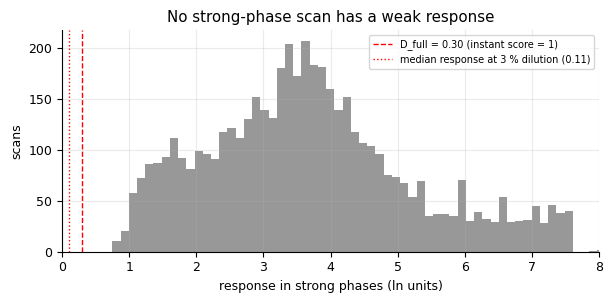

In [10]:
strong = np.isin(D["phase"], STRONG_PHASES)
resp = RD[strong]
q = np.quantile(resp, [0.05, 0.25, 0.5, 0.75, 0.95])
print("Size of the recorded response in strong smoke (drop of ln R vs clean start):")
print("  5 %, 25 %, 50 %, 75 %, 95 % :", " ".join(f"{v:.2f}" for v in q), f"| minimum {resp.min():.2f}")
live_strong = live & strong
print("\nRecall by size of the physical response (undiluted data, strong phases):")
for lo, hi in ((-9, 0.3), (0.3, 0.5), (0.5, 1), (1, 2), (2, 4), (4, 99)):
    mm = live_strong & (RD >= lo) & (RD < hi)
    print(f"  response in [{max(lo, -9):>4}, {hi:>3}) ln: {mm.sum():>5} scans" + (f", recall {(res['cls'][mm] == SMOKE).mean():.3f}" if mm.any() else "  (no data)"))

fig, ax = plt.subplots(figsize=(6.2, 3.1))
ax.hist(resp, bins=60, color="#7f7f7f", alpha=0.8)
ax.axvline(0.30, color="r", ls="--", lw=1, label="D_full = 0.30 (instant score = 1)")
ax.axvline(0.03 * q[2], color="r", ls=":", lw=1, label=f"median response at 3 % dilution ({0.03 * q[2]:.2f})")
ax.set(xlabel="response in strong phases (ln units)", ylabel="scans", xlim=(0, 8), title="No strong-phase scan has a weak response"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading.** The weakest strong-phase scan still drops by 0.75 $\ln$ units (printed minimum), and recall is 1.000 in every populated bin. So the recordings contain **no weak response at all**: the chain's sensitivity cannot be measured on the undiluted data, and a distant or small fire is exactly the case that is missing.

**Distance proxy.** To probe the weak range, the part of $\ln R$ added by the fire is scaled by a factor $f$ (`dilute`), keeping the sensor noise at its clean-air level. The truth is "strong phase and physical response of at least 0.1 ln".

 factor  recall 2021  recall 2025  false smoke   (truth: strong phase and response >= 0.1 ln)
      1        1.000        1.000         1.4 %
    0.5        1.000        1.000         0.5 %
   0.25        1.000        0.999         0.5 %
   0.12        1.000        0.995         0.5 %
   0.06        1.000        0.986         0.5 %
   0.03        1.000        0.944         0.3 %


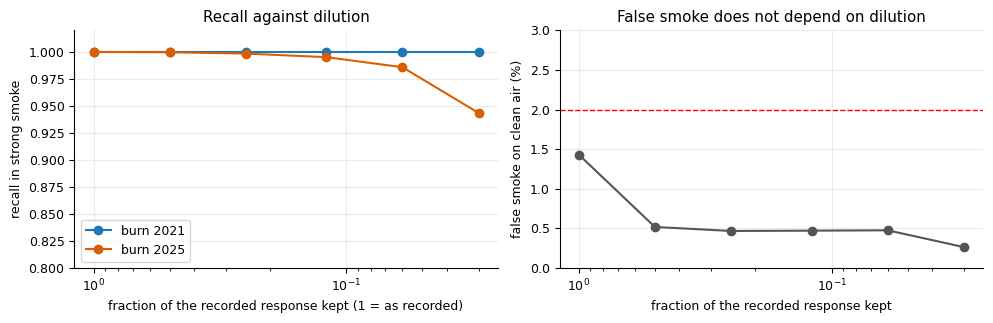

In [11]:
factors = [1, 0.5, 0.25, 0.12, 0.06, 0.03]
curve = {"2021": [], "2025": []}
false_rate = []
print(f"{'factor':>7} {'recall 2021':>12} {'recall 2025':>12} {'false smoke':>12}   (truth: strong phase and response >= 0.1 ln)")
for f in factors:
    Df = dilute(D, f)
    r = replay(Df)
    rd = response_depth(Df)
    vals = []
    for e in ("2021", "2025"):
        mm = (~r["warmup"]) & (D["experiment"] == e) & np.isin(D["phase"], STRONG_PHASES) & (rd >= 0.1)
        v = float(np.mean(r["cls"][mm] == SMOKE)); curve[e].append(v); vals.append(v)
    fr = metrics(Df, r, None, 2)["false_smoke_clean"]; false_rate.append(fr)
    print(f"{f:>7} {vals[0]:>12.3f} {vals[1]:>12.3f} {fr*100:>11.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for e in ("2021", "2025"):
    ax[0].plot(factors, curve[e], "o-", color=BURN_COLOR[e], label=f"burn {e}")
ax[0].set_xscale("log"); ax[0].invert_xaxis(); ax[0].set_ylim(0.8, 1.02); ax[0].legend()
ax[0].set(xlabel="fraction of the recorded response kept (1 = as recorded)", ylabel="recall in strong smoke", title="Recall against dilution")
ax[1].plot(factors, np.array(false_rate) * 100, "o-", color="#555")
ax[1].set_xscale("log"); ax[1].invert_xaxis(); ax[1].axhline(2, color="r", ls="--", lw=1); ax[1].set_ylim(0, 3)
ax[1].set(xlabel="fraction of the recorded response kept", ylabel="false smoke on clean air (%)", title="False smoke does not depend on dilution")
plt.tight_layout(); plt.show()

**Reading.**
- Recall stays at 0.986 or more down to 6 % of the recorded strength, and drops to 0.944 (2025) at 3 %. False smoke stays flat, as it should: dilution only touches the part of the signal added by the fire, and clean air is untouched.
- The curve is **optimistic**. Scaling is linear and the sensor noise is kept, but a distant plume also mixes with other gases and arrives in puffs, and the truth rule keeps only the strongest scans at low factors.
- The earlier project log reported a much earlier loss of recall. Those numbers use another truth rule and another chain: they are **not reproduced and not comparable**.
- **Decision.** No sensitivity claim beyond "the chain does not limit sensitivity on this data". The range of distances must be measured with own recordings.

## 9. Verdict and limits

In [12]:
checks = []
for e in ("2021", "2025"):
    m = metrics(D, res, e, start_phase=2)
    checks += [(f"false smoke on clean air <= 2 %, burn {e}", m["false_smoke_clean"] <= 0.02, f"{m['false_smoke_clean']*100:.1f} %"),
               (f"recall in strong smoke >= 0.95, burn {e}", m["recall_strong"] >= 0.95, f"{m['recall_strong']:.3f}"),
               (f"fault inside strong smoke <= 1 %, burn {e}", m["fault_in_strong"] <= 0.01, f"{m['fault_in_strong']*100:.1f} %")]
for name, ok, val in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {val}")
print(f"\n{sum(c[1] for c in checks)} of {len(checks)} criteria pass.")

PASS  false smoke on clean air <= 2 %, burn 2021: 0.0 %
PASS  recall in strong smoke >= 0.95, burn 2021: 1.000
PASS  fault inside strong smoke <= 1 %, burn 2021: 0.0 %
PASS  false smoke on clean air <= 2 %, burn 2025: 1.9 %
PASS  recall in strong smoke >= 0.95, burn 2025: 1.000
PASS  fault inside strong smoke <= 1 %, burn 2025: 0.0 %

6 of 6 criteria pass.


### What the evidence supports

| Claim | Status | Basis |
|---|---|---|
| Default settings meet the six criteria on both burns | **supported** | section 3 |
| Strong smoke is always found and never read as a fault | **supported** on these recordings | recall 1.000, fault 0.0 % |
| The detection delay is about 3 minutes | **supported at the recorded pace** (25 to 27 s per scan) | not measured at the Eco pace (300 s) |
| False smoke comes from a few episodes with a slow scan and few clean scans | **supported as a correlation**, 4 episodes of one node | section 4 |
| A false alarm latches and cannot recover | **observed** on the 4 episodes, mechanism reasoned from the plots | section 4 |
| Compensation fitted on one burn transfers to the other | **not supported** | section 5 |
| Longer burn-in or warm-up cures power-on drift | **not supported** | section 6 |
| The median of 5 costs about one minute | **supported** | section 7 |
| Sensitivity to weak or distant smoke | **cannot be measured** on this data; the diluted curve is a proxy | section 8 |

### Threats to validity
- **Another sensor.** BME688/690 data, BME680 on the box.
- **Two burns, one experiment series.** Scans are correlated; the rates describe these recordings.
- **Few evaluable clean starts.** 8 episodes of 2025 contribute nothing to the false-smoke rate, and the 2025 figure rests on 4 failing episodes of one node.
- **Undocumented phase tags.** The truth labels are the order of the phases, checked against the physical response (section 2), not an authors' ground truth.
- **No decoys, no other fuels, no wind, no temperature sweep.** The chain has not been tested against steam, cooking fumes, dust or a changing room.
- **Scan pace.** All counts are in scans; the box scans every 300 s in Eco mode.

### Next
1. Own BME680 recordings (incense, smouldering wood, indoors) with a temperature and humidity sweep; re-run this notebook on them.
2. Replay the real data at the Eco pace (300 s) to measure the delay and the clean-air behaviour there.
3. Test remedies for the latching false alarm (release rule, baseline saved in flash).
4. Define the 10-step heater profile of the BME680.

### Reproduce
`cd ai-data/box/gas_chain/python/notebooks && python3 ../../../../tools/run_notebook.py 01_real_data_evaluation.ipynb`. The full data set is not versioned (see `ai-data/data/README.md`; set `CAS_MENDELEY_DIR` if it is elsewhere). Runtime about one minute. Settings are the defaults of `Config`; the dilution uses a fixed random seed.